<a href="https://colab.research.google.com/github/Intexes/ARIMA-model/blob/main/%D0%9F%D1%80%D0%BE%D0%B5%D0%BA%D1%82_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
uploaded_1 = files.upload()
chocolate = pd.read_csv(next(iter(uploaded_1)))
display(chocolate)

Saving Chocolate_Sales.csv to Chocolate_Sales.csv


,Sales Person,Country,Product,Date,Amount,Boxes Shipped
0,Jehu Rudeforth,UK,Mint Chip Choco,04-Jan-22,"$5,320",180
1,Van Tuxwell,India,85% Dark Bars,01-Aug-22,"$7,896",94
2,Gigi Bohling,India,Peanut Butter Cubes,07-Jul-22,"$4,501",91
3,Jan Morforth,Australia,Peanut Butter Cubes,27-Apr-22,"$12,726",342
4,Jehu Rudeforth,UK,Peanut Butter Cubes,24-Feb-22,"$13,685",184
...,...,...,...,...,...,...
1089,Karlen McCaffrey,Australia,Spicy Special Slims,17-May-22,"$4,410",323
1090,Jehu Rudeforth,USA,White Choc,07-Jun-22,"$6,559",119
1091,Ches Bonnell,Canada,Organic Choco Syrup,26-Jul-22,$574,217
1092,Dotty Strutley,India,Eclairs,28-Jul-22,"$2,086",384


Часть 1. Предобработка данных

Для исследования анализа клиентской базы мы подобрали датасет по продажам шоколада, который включает столбцы с именем пользователя, датой заказа, суммой и страной покупки:

In [ ]:
display(chocolate.head())
chocolate.info()

,Sales Person,Country,Product,Date,Amount,Boxes Shipped
0,Jehu Rudeforth,UK,Mint Chip Choco,04-Jan-22,"$5,320",180
1,Van Tuxwell,India,85% Dark Bars,01-Aug-22,"$7,896",94
2,Gigi Bohling,India,Peanut Butter Cubes,07-Jul-22,"$4,501",91
3,Jan Morforth,Australia,Peanut Butter Cubes,27-Apr-22,"$12,726",342
4,Jehu Rudeforth,UK,Peanut Butter Cubes,24-Feb-22,"$13,685",184


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1094 entries, 0 to 1093
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Sales Person   1094 non-null   object
 1   Country        1094 non-null   object
 2   Product        1094 non-null   object
 3   Date           1094 non-null   object
 4   Amount         1094 non-null   object
 5   Boxes Shipped  1094 non-null   int64 
dtypes: int64(1), object(5)
memory usage: 51.4+ KB


Как мы видим, датасет содержит дату в формате object, этот формат нужно изменить для дальнейшего корректного изучения данных

In [ ]:
chocolate['Date'] = pd.to_datetime(chocolate['Date'])
chocolate.info()

chocolate['Amount'] = chocolate['Amount'].str.replace('[\$,]', '', regex=True)

chocolate['Amount'] = chocolate['Amount'].astype(int)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1094 entries, 0 to 1093
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Sales Person   1094 non-null   object        
 1   Country        1094 non-null   object        
 2   Product        1094 non-null   object        
 3   Date           1094 non-null   datetime64[ns]
 4   Amount         1094 non-null   object        
 5   Boxes Shipped  1094 non-null   int64         
dtypes: datetime64[ns](1), int64(1), object(4)
memory usage: 51.4+ KB


<>:4: SyntaxWarning: invalid escape sequence '\$'
<>:4: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipython-input-841412678.py:4: SyntaxWarning: invalid escape sequence '\$'
  chocolate['Amount'] = chocolate['Amount'].str.replace('[\$,]', '', regex=True)
/tmp/ipython-input-841412678.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chocolate['Date'] = pd.to_datetime(chocolate['Date'])


После изменения формата столбца, необходимо выявить кол-во уникальных пользователей делавщих заказ,

In [ ]:
print(chocolate['Sales Person'].nunique())
print(chocolate['Country'].nunique())
count_unique = chocolate.drop_duplicates(subset=['Sales Person', 'Country']).shape[0]
print(f"Количество уникальных людей с заказами: {count_unique}")
print(chocolate['Product'].unique())

25
6
Количество уникальных людей с заказами: 150
['Mint Chip Choco' '85% Dark Bars' 'Peanut Butter Cubes'
 'Smooth Sliky Salty' '99% Dark & Pure' 'After Nines' '50% Dark Bites'
 'Orange Choco' 'Eclairs' 'Drinking Coco' 'Organic Choco Syrup'
 'Milk Bars' 'Spicy Special Slims' 'Fruit & Nut Bars' 'White Choc'
 'Manuka Honey Choco' 'Almond Choco' 'Raspberry Choco'
 'Choco Coated Almonds' "Baker's Choco Chips" 'Caramel Stuffed Bars'
 '70% Dark Bites']


АНАЛИЗ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ:

Зададим категории прокдуктам, чтобы было легче анализировать датасет

In [ ]:
def assign_product_category(product_name):
    name_lower = product_name.lower()
    if any(keyword in name_lower for keyword in ['dark', 'dark bars', 'dark & pure']):
        return 'Темный шоколад'
    elif 'choco' in name_lower or 'cocoa' in name_lower:
        return 'Шоколад'
    elif 'peanut' in name_lower or 'almond' in name_lower:
        return 'Ореховые'
    elif 'fruit' in name_lower or 'berry' in name_lower:
        return 'Фруктовые'
    elif 'honey' in name_lower:
        return 'Медовые'
    elif 'caramel' in name_lower:
        return 'Карамельные'
    elif 'eclairs' in name_lower or 'syrup' in name_lower:
        return 'Десертные'
    elif 'bites' in name_lower:
        return 'Маленькие батончики'
    else:
        return 'Другое'

chocolate['Category'] = chocolate['Product'].apply(assign_product_category)

print(chocolate.head())

count_by_category = chocolate.groupby('Category').size()

print(count_by_category)

     Sales Person    Country              Product       Date  Amount  \
0  Jehu Rudeforth         UK      Mint Chip Choco 2022-01-04    5320   
1     Van Tuxwell      India        85% Dark Bars 2022-08-01    7896   
2    Gigi Bohling      India  Peanut Butter Cubes 2022-07-07    4501   
3    Jan Morforth  Australia  Peanut Butter Cubes 2022-04-27   12726   
4  Jehu Rudeforth         UK  Peanut Butter Cubes 2022-02-24   13685   

   Boxes Shipped        Category  
0            180         Шоколад  
1             94  Темный шоколад  
2             91        Ореховые  
3            342        Ореховые  
4            184        Ореховые  
Category
Десертные          60
Другое            326
Карамельные        43
Ореховые           49
Темный шоколад    201
Фруктовые          50
Шоколад           365
dtype: int64


Далее выделим категориальные столбцы (Страну и Категорию шоколада) и посчитаем кол-во уникальных значений

In [ ]:
print(chocolate['Country'].unique())
print(chocolate['Country'].nunique())

print(chocolate['Category'].unique())
print(chocolate['Category'].nunique())


['UK' 'India' 'Australia' 'New Zealand' 'USA' 'Canada']
6
['Шоколад' 'Темный шоколад' 'Ореховые' 'Другое' 'Десертные' 'Фруктовые'
 'Карамельные']
7


Так же для удобства обращения с информацией выделим людей с одинаковым именем и страной уникальным номером индефикатором

In [ ]:
chocolate['Person_Country_Key'] = chocolate['Sales Person'] + '|' + chocolate['Country']

chocolate['User_ID'] = pd.factorize(chocolate['Person_Country_Key'])[0] + 1

chocolate.drop('Person_Country_Key', axis=1, inplace=True)

print(chocolate)

          Sales Person    Country              Product       Date  Amount  \
0       Jehu Rudeforth         UK      Mint Chip Choco 2022-01-04    5320   
1          Van Tuxwell      India        85% Dark Bars 2022-08-01    7896   
2         Gigi Bohling      India  Peanut Butter Cubes 2022-07-07    4501   
3         Jan Morforth  Australia  Peanut Butter Cubes 2022-04-27   12726   
4       Jehu Rudeforth         UK  Peanut Butter Cubes 2022-02-24   13685   
...                ...        ...                  ...        ...     ...   
1089  Karlen McCaffrey  Australia  Spicy Special Slims 2022-05-17    4410   
1090    Jehu Rudeforth        USA           White Choc 2022-06-07    6559   
1091      Ches Bonnell     Canada  Organic Choco Syrup 2022-07-26     574   
1092    Dotty Strutley      India              Eclairs 2022-07-28    2086   
1093  Karlen McCaffrey      India       70% Dark Bites 2022-05-23    5075   

      Boxes Shipped        Category  User_ID  
0               180         

АНАЛИЗ ЧИСЛОВЫХ ПРИЗНАКОВ:

Построим диаграммы для нахождения выбросов и аномалий

In [ ]:
import plotly.express as px

fig = px.box(chocolate, 'Amount', title = 'Распределение суммы купленных продуктов')
fig.show()

Так как мы видим ассиметричное распределение, избавление от выбросов не имеет смысла

ОБРАБОТАЕМ ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ:

Для датасета найдем строки, в которых пропущены значения, чтобы исключить не релевантные данные для дальнейших вычислений

In [ ]:
rows_with_na = chocolate.isna().sum()

print(rows_with_na)

Sales Person     0
Country          0
Product          0
Date             0
Amount           0
Boxes Shipped    0
Category         0
User_ID          0
dtype: int64


Так как пропусков нет, нет необходимости удалять строки

ОБРАБОТАЕМ ДУБЛИРУЮЩИЕ ЗНАЧЕНИЯ:

Среди строк найдем полностью повторяющиеся, чтобы исключить ошибку дублирования данных

In [ ]:
rows_with_dupplicates = chocolate.duplicated().sum()
print(rows_with_dupplicates)

0


Дубликатов нет, следовательно множно переходить к следующему шагу

Часть 2. Разведочный анализ данных (Exploratory Data Analysis — EDA)


АНАЛИЗ ДИНАМИКИ ВЫРУЧКИ:

Построим графики динамики общей выручки: по дням недели, по кварталам и по месяцам

In [ ]:
chocolate_profit = chocolate.loc[:,['Amount', 'Date']]
chocolate_profit['Month'] = chocolate_profit['Date'].dt.month

month_mapping = {
    1: 'Январь',
    2: 'Февраль',
    3: 'Март',
    4: 'Апрель',
    5: 'Май',
    6: 'Июнь',
    7: 'Июль',
    8: 'Август',
    9: 'Сентябрь',
    10: 'Октябрь',
    11: 'Ноябрь',
    12: 'Декабрь'

}

chocolate_profit['Month_name'] = chocolate_profit['Month'].map(month_mapping)

chocolate_profit['Day_of_week'] = chocolate_profit['Date'].dt.day_of_week

day_mapping = {
    0: 'Понедельник',
    1: 'Вторник',
    2: 'Среда',
    3: 'Четверг',
    4: 'Пятница',
    5: 'Суббота',
    6: 'Воскресенье'
}

chocolate_profit['Day_of_week_name'] = chocolate_profit['Day_of_week'].map(day_mapping)
chocolate_profit['Quartal'] = chocolate_profit['Date'].dt.quarter
display(chocolate_profit)

,Amount,Date,Month,Month_name,Day_of_week,Day_of_week_name,Quartal
0,5320,2022-01-04,1,Январь,1,Вторник,1
1,7896,2022-08-01,8,Август,0,Понедельник,3
2,4501,2022-07-07,7,Июль,3,Четверг,3
3,12726,2022-04-27,4,Апрель,2,Среда,2
4,13685,2022-02-24,2,Февраль,3,Четверг,1
...,...,...,...,...,...,...,...
1089,4410,2022-05-17,5,Май,1,Вторник,2
1090,6559,2022-06-07,6,Июнь,1,Вторник,2
1091,574,2022-07-26,7,Июль,1,Вторник,3
1092,2086,2022-07-28,7,Июль,3,Четверг,3


График распределения по месяцам

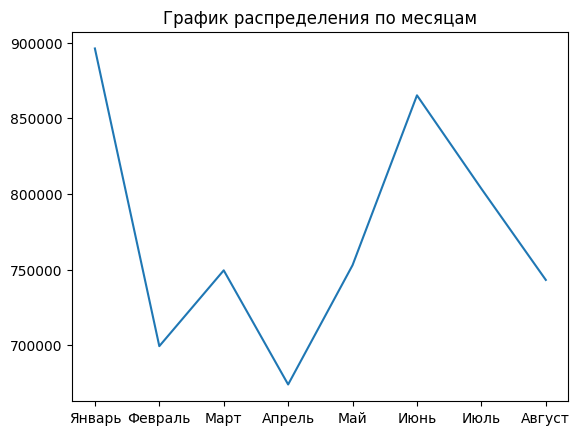

In [ ]:
table_1 = chocolate_profit.groupby(['Month', 'Month_name'])['Amount'].sum().reset_index()
plt.plot(table_1['Month_name'],table_1['Amount'])
plt.title('График распределения по месяцам')
plt.show()

Исходя из графика месяных продаж можно заметить что пики продаж шоколада приходятся на Январь и Июнь, можно предположить что в эти месяцы люди могут дарить подарки на праздники или покупать шоколад из-за большого кол-ва дней для отдыха.

График распределения по дням недели

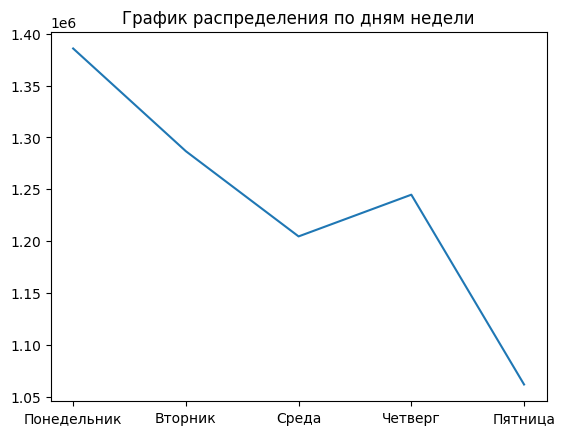

In [ ]:
table_1 = chocolate_profit.groupby(['Day_of_week', 'Day_of_week_name'])['Amount'].sum().reset_index()
plt.plot(table_1['Day_of_week_name'],table_1['Amount'])
plt.title('График распределения по дням недели')
plt.show()

Исходя из графика распределения покупок нельзя точно определить зависимости от дня недели, нужны более точные данные, можно с уверенностью заявить что спрос снижается постепенно на протяжении недели.

График распределения по кварталам

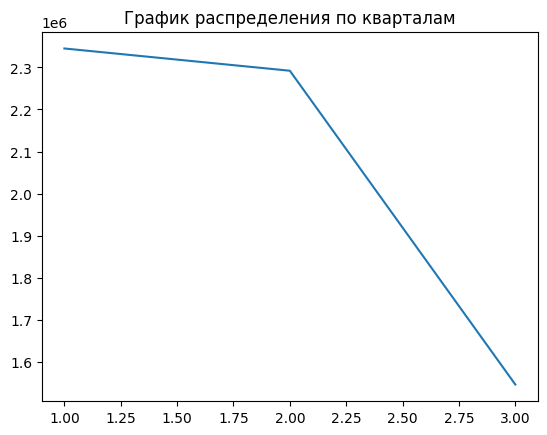

In [ ]:
table_1 = chocolate_profit.groupby(['Quartal'])['Amount'].sum().reset_index()
plt.plot(table_1['Quartal'],table_1['Amount'])
plt.title('График распределения по кварталам')

plt.show()

Исходя из графика распределения по кварталам нельзя четко выразить причину значительного спада в 3 периоде, необходимы дополнительные данные для исследования данного явления.

Часть 3. Статистический анализ и сегментация

ПРОВЕРКА СТАТИСТИЧЕСКИХ ГИПОТЕЗ:


Проведем анализ зависимости средней выручки шоколада от категориальных признаков и составим гипотезы:

H0 - Нет статистического различия между группами востока и запада по прибыли

H1 - Есть статистическое различие между группами востока и запада по прибыли

In [ ]:
from scipy.stats import shapiro, mannwhitneyu
display(chocolate)
print(chocolate['Country'].unique())

,Sales Person,Country,Product,Date,Amount,Boxes Shipped,Category,User_ID
0,Jehu Rudeforth,UK,Mint Chip Choco,2022-01-04,5320,180,Шоколад,1
1,Van Tuxwell,India,85% Dark Bars,2022-08-01,7896,94,Темный шоколад,2
2,Gigi Bohling,India,Peanut Butter Cubes,2022-07-07,4501,91,Ореховые,3
3,Jan Morforth,Australia,Peanut Butter Cubes,2022-04-27,12726,342,Ореховые,4
4,Jehu Rudeforth,UK,Peanut Butter Cubes,2022-02-24,13685,184,Ореховые,1
...,...,...,...,...,...,...,...,...
1089,Karlen McCaffrey,Australia,Spicy Special Slims,2022-05-17,4410,323,Другое,106
1090,Jehu Rudeforth,USA,White Choc,2022-06-07,6559,119,Другое,143
1091,Ches Bonnell,Canada,Organic Choco Syrup,2022-07-26,574,217,Шоколад,124
1092,Dotty Strutley,India,Eclairs,2022-07-28,2086,384,Десертные,138


['UK' 'India' 'Australia' 'New Zealand' 'USA' 'Canada']


Для понимания распределения необходимо разделить список стран на западные и восточные

In [ ]:
east_countries = ['India', 'Australia', 'New Zealand']
west_countries = ['USA', 'Canada', 'UK']

Далее необходимо найти нормальность распределения данных по регионам

In [ ]:
east_region = chocolate[chocolate['Country'].isin(east_countries)]
west_region = chocolate[chocolate['Country'].isin(west_countries)]

east_amounts = east_region['Amount']
west_amounts = west_region['Amount']

stat_east, p_east = shapiro(east_amounts)
stat_west, p_west = shapiro(west_amounts)

print(f"Нормальность Восток: p = {p_east}")
print(f"Нормальность Запад: p = {p_west}")

Нормальность Восток: p = 8.20935880955161e-15
Нормальность Запад: p = 8.411583718877155e-15


Так как нормальности распределения в обоих случаях нет, необходимость в проведении теста Левина на нахождение равенства дисперсий отпадает. Следовательно нужно использовать тест Манна-Уитни

In [ ]:
p_value = mannwhitneyu(east_amounts, west_amounts)[1]
print(f"Manna-Whitneyu: p-value = {p_value}")

Manna-Whitneyu: p-value = 0.7030689345813745


Так как P-value > 0.05, следовательно принимается гипотеза H0 - Нет статистического различия между группами востока и запада по прибыли

Для наглядного отображения посторим график прибыли по группам и сравним медианы обеих групп

In [ ]:
display(chocolate)

,Sales Person,Country,Product,Date,Amount,Boxes Shipped,Category,User_ID
0,Jehu Rudeforth,UK,Mint Chip Choco,2022-01-04,5320,180,Шоколад,1
1,Van Tuxwell,India,85% Dark Bars,2022-08-01,7896,94,Темный шоколад,2
2,Gigi Bohling,India,Peanut Butter Cubes,2022-07-07,4501,91,Ореховые,3
3,Jan Morforth,Australia,Peanut Butter Cubes,2022-04-27,12726,342,Ореховые,4
4,Jehu Rudeforth,UK,Peanut Butter Cubes,2022-02-24,13685,184,Ореховые,1
...,...,...,...,...,...,...,...,...
1089,Karlen McCaffrey,Australia,Spicy Special Slims,2022-05-17,4410,323,Другое,106
1090,Jehu Rudeforth,USA,White Choc,2022-06-07,6559,119,Другое,143
1091,Ches Bonnell,Canada,Organic Choco Syrup,2022-07-26,574,217,Шоколад,124
1092,Dotty Strutley,India,Eclairs,2022-07-28,2086,384,Десертные,138


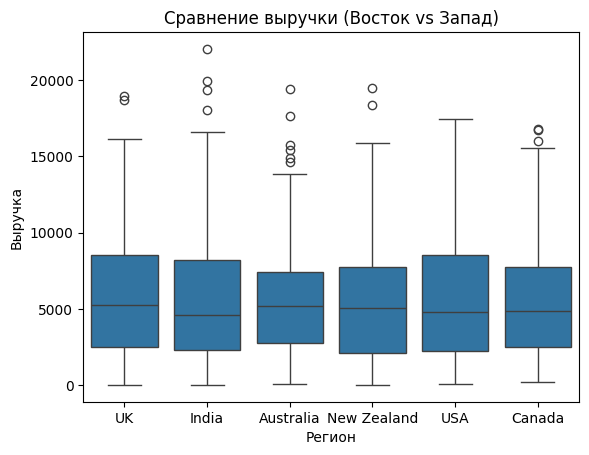

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.boxplot(x='Country', y='Amount', data=chocolate)
plt.title('Сравнение выручки (Восток vs Запад)')
plt.xlabel('Регион')
plt.ylabel('Выручка')
plt.show()

In [ ]:
east_total_amount = east_region['Amount'].mean()
west_total_amount = west_region['Amount'].mean()

print(f"Общий `Amount` для Восточного региона: {east_total_amount}")
print(f"Общий `Amount` для Западного региона: {west_total_amount}")

Общий `Amount` для Восточного региона: 5575.774021352313
Общий `Amount` для Западного региона: 5733.1578947368425


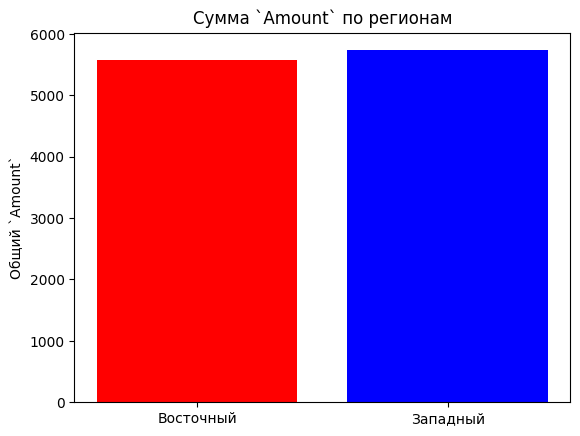

In [ ]:
regions = ['Восточный', 'Западный']
amounts = [east_total_amount, west_total_amount]

plt.bar(regions, amounts, color=['red', 'blue'])
plt.ylabel('Общий `Amount`')
plt.title('Сумма `Amount` по регионам')
plt.show()

Как видно исходя из графика - существенных отличий в регионах нет

RFM-АНАЛИЗ:

In [ ]:
import datetime as dt
max_date = chocolate['Date'].max()

rfm = chocolate.groupby('User_ID').agg({
    'Date': lambda x: (max_date - x.max()).days,
    'User_ID': 'count',
    'Amount': 'sum'
    }).rename(columns={
    'Date': 'Recency',
    'User_ID': 'Frequency',
    'Amount': 'Monetary'})

rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=False, duplicates='drop')
rfm['F_Score'] = pd.qcut(rfm['Frequency'], 5, labels=False, duplicates='drop')
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=False, duplicates='drop')

def segment(r, f, m):
    if r >= 4 and f >= 4 and m >= 4:
        return 'Лояльные'
    elif r >= 2 and f >= 2 and m >= 2:
        return 'Средние'
    else:
        return 'Незначительные'

rfm['Segment'] = rfm.apply(lambda row: segment(row['R_Score'], row['F_Score'], row['M_Score']), axis=1)

In [ ]:
print(rfm)

         Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
User_ID                                                            
1              7         12     69895        0        4        4   
2             30         11     85785        3        4        4   
3             55          5     16905        4        0        0   
4             35          7     48468        3        1        3   
5             44         10     69279        3        4        4   
...          ...        ...       ...      ...      ...      ...   
146           35          3     29967        3        0        1   
147           19          7     37499        1        1        2   
148           13          8     35973        1        2        1   
149            9          5     23996        1        0        0   
150           23          2      8428        2        0        0   

                Segment  
User_ID                  
1        Незначительные  
2               Средние  
3        Не

Часть 4. Прогнозирование выручки с использованием моделей временных рядов

In [ ]:
chocolate_time = chocolate[['Date', 'Amount']]
chocolate_time.head()

,Date,Amount
0,2022-01-04,5320
1,2022-08-01,7896
2,2022-07-07,4501
3,2022-04-27,12726
4,2022-02-24,13685


In [ ]:
chocolate_time['Date'] = pd.to_datetime(chocolate_time['Date'])
chocolate_time.set_index('Date', inplace=True)

/tmp/ipython-input-806590495.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



Выберем недельное разделение для данных, так как для ARIMA моделирования нужно не менее 50 опорных точек (в нашем случае 81, что является допустимым)

In [ ]:
chocolate_time_days = chocolate_time['Amount'].resample('3D').sum()
display(chocolate_time_days)

,Amount
Date,
2022-01-03,146762
2022-01-06,8666
2022-01-09,82873
2022-01-12,158242
2022-01-15,42063
...,...
2022-08-19,29134
2022-08-22,134162
2022-08-25,57897


Для наглядности построим график временного ряда

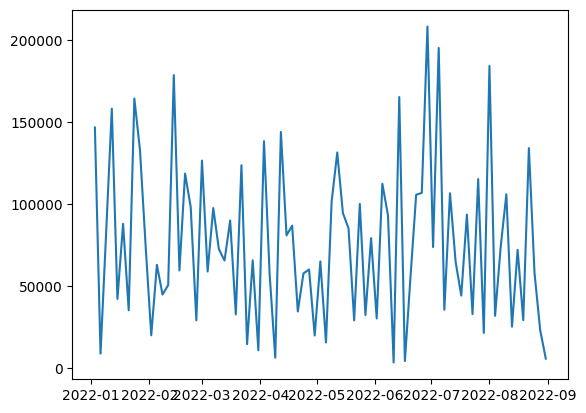

In [ ]:
plt.plot(chocolate_time_days.index, chocolate_time_days.values)
plt.show()

Проведем

Text(0.5, 1.0, '\nОстатки')

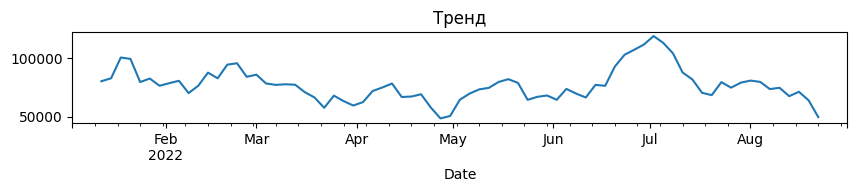

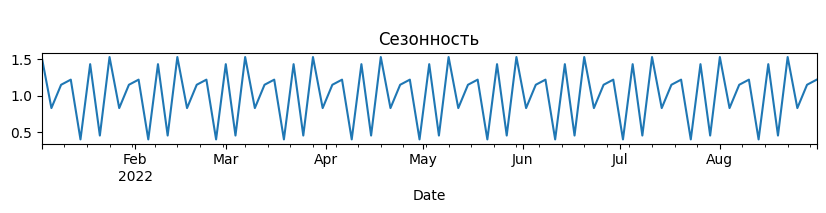

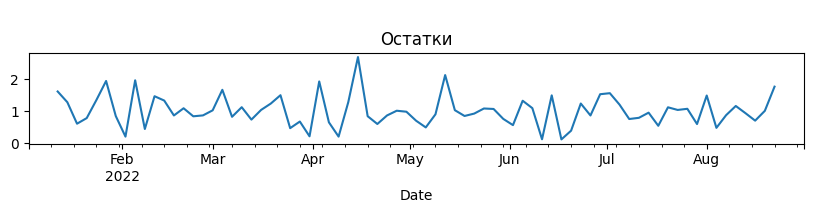

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposed = seasonal_decompose(
    chocolate_time_days,
    model='multiplicative',  # мультипликативная, так как амплитуда колебаний растет
    # period=3,                # 3 месяца = квартальная сезонность
    #extrapolate_trend='freq'
    )

# Тренд
fig = plt.figure(figsize=(10, 4))
plt.subplot(311)
decomposed.trend.plot(ax=plt.gca()) #gca - чтобы график корректно отобразился (именно оси)
plt.title('Тренд')

# Cезонность
fig = plt.figure(figsize=(10, 4))
plt.subplot(312)
decomposed.seasonal.plot(ax=plt.gca())
plt.title('\nСезонность')

# Остатки
fig = plt.figure(figsize=(10, 4))
plt.subplot(313)
decomposed.resid.plot(ax=plt.gca())
plt.title('\nОстатки')

Для проверки стационарности проведем тест Фуллера

In [ ]:
from statsmodels.tsa.stattools import adfuller

p_value = adfuller(chocolate_time_days.values)[1]
print(p_value)

0.05915483465134755


Ряд не стационарен, так как p-значение > 0.05, нужно использовать логарифмирование

In [ ]:
import numpy as np

data_log = np.log(chocolate_time_days)
p_value = adfuller(data_log.values)[1]
print(p_value)

0.04101530386597757


Ряд стационарен

Построим графики ACF и PACF

Text(0.5, 1.0, 'PACF')

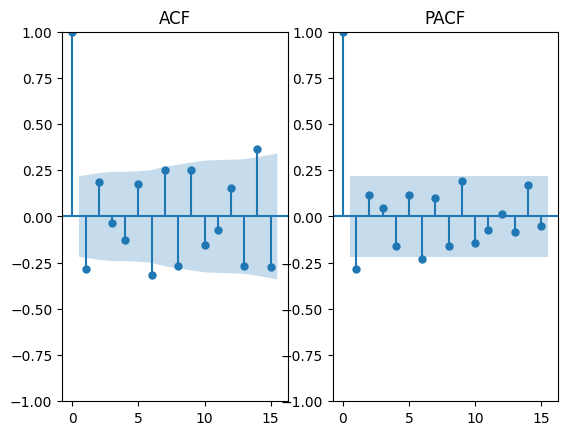

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.subplot(121)
plot_acf(data_log, ax=plt.gca(), lags=15)
plt.title('ACF')

plt.subplot(122)
plot_pacf(data_log, ax=plt.gca(), lags=15)
plt.title('PACF')

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error

train_size = int(len(data_log)*0.7)
train = data_log[:train_size]
test = data_log[train_size:]

model = ARIMA(train, order=(1,1,1))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                 Amount   No. Observations:                   56
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 -72.205
Date:                Tue, 16 Dec 2025   AIC                            150.409
Time:                        14:30:44   BIC                            156.431
Sample:                    01-03-2022   HQIC                           152.738
                         - 06-17-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4218      0.182     -2.315      0.021      -0.779      -0.065
ma.L1         -0.9235      0.090    -10.288      0.000      -1.099      -0.748
sigma2         0.7690      0.126      6.109      0.0

Модель идеальна для прогнозирования, так как п значения у всех параметров значимы, сигма 2 имеет нормальное значение

In [ ]:
forecast = model_fit.forecast(steps= len(test))
forecast_index = test.index

mse = mean_squared_error(test, forecast)
rmse = np.sqrt(mse)
mae = mean_absolute_error(test, forecast)
mape = np.mean(np.abs((test-forecast)/test))*100

print(f'mse:{mse}')
print(f'rmse:{rmse}')
print(f'mae:{mae}')
print(f'mape:{mape}')

mse:0.8171865483926456
rmse:0.9039837102473947
mae:0.766333457477038
mape:6.991802265713595


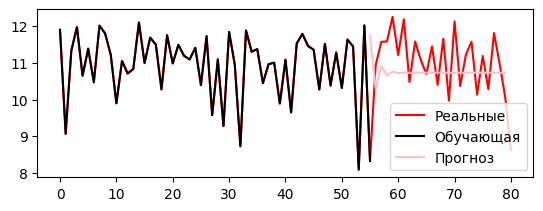

In [ ]:
plt.subplot(2,1,1)

full_data = np.concatenate([train.values, test.values])
plt.plot(range(len(full_data)), full_data, label='Реальные', color='red')
plt.plot(range(len(train)), train.values, label='Обучающая', color='black')
plt.plot(range(len(train)-1, len(train)-1 + len(forecast)), forecast, label='Прогноз', color='pink')
plt.legend()
plt.show()

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox
residuals = model_fit.resid
lb_test = acorr_ljungbox(residuals, lags=10)
print(lb_test)

     lb_stat  lb_pvalue
1   1.671709   0.196030
2   1.680876   0.431521
3   2.207482   0.530476
4   2.208300   0.697510
5   2.324806   0.802617
6   2.618987   0.854921
7   2.845354   0.898930
8   3.042858   0.931639
9   3.356632   0.948464
10  4.021665   0.946364


Тест Юнга-Бокса показал значимость каждого из 10 лагов

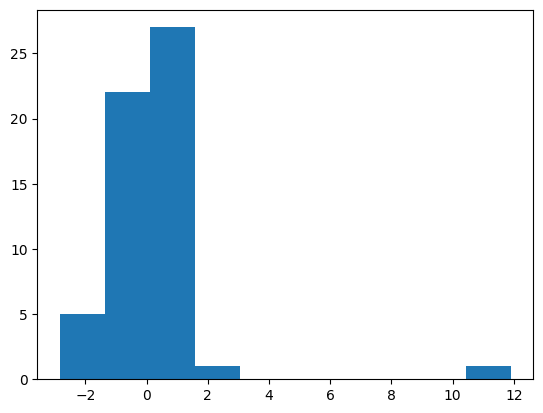

In [ ]:
plt.hist(residuals, bins=10)
plt.show()

Наблюдается приблизительно нормальное распределение, с явным выбросом на окончании графика

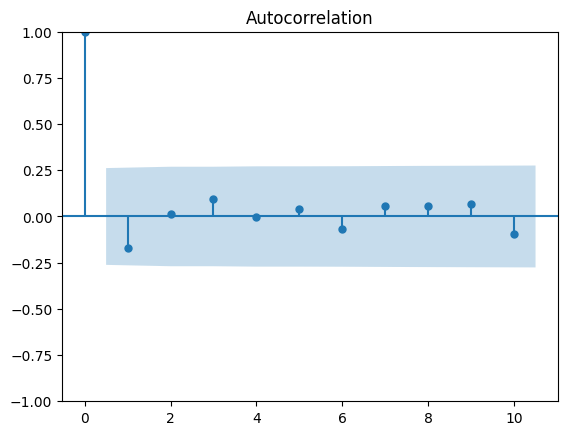

In [ ]:
plot_acf(residuals, lags=10)
plt.show()

Нет значимых остатков автокорреляции

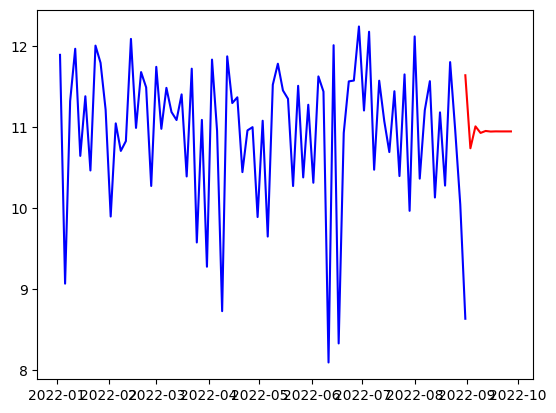

2022-08-31: 11.64
2022-09-03: 10.74
2022-09-06: 11.01
2022-09-09: 10.93
2022-09-12: 10.96
2022-09-15: 10.95
2022-09-18: 10.95
2022-09-21: 10.95
2022-09-24: 10.95
2022-09-27: 10.95


In [ ]:
final_model = ARIMA(data_log, order=(1,1,1))
final_model_fit = final_model.fit()
future_step = 10
future_forecast = final_model_fit.forecast(steps=future_step)

last_date = data_log.index[-1]
future_dates = pd.date_range(start = last_date +pd.Timedelta(days=0),
                             periods = future_step, freq='3D')
plt.plot(data_log.index, data_log.values, color = 'blue')
plt.plot(future_dates, future_forecast, color = 'red')
plt.show()

for date, value in zip(future_dates, future_forecast):
  print(f"{date.strftime('%Y-%m-%d')}: {value:.2f}")